# Задание 2.2. Кластеризация PPG
Королев Даниил, группа 636-02.

Попробовал разделить окна PPG на три кластера без меток активности.
Сравнил общую нормализацию с нормализацией внутри каждого испытуемого.
Метки читаю только после того, как метод и внешние прогнозы уже зафиксированы.
Условие: https://github.com/AI-is-out-there/check-your-biomed-datascience-skills-review/blob/main/task/task2-2_ppg_unsupervised_clustering.md

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import platform

import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import Markdown, display
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.signal import butter, find_peaks, sosfiltfilt, welch
from scipy.stats import kurtosis, skew
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

SEED, N_CLUSTERS = 42, 3
THREAD_LIMITER = threadpool_limits(limits=1)
np.random.seed(SEED)
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=0.9)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})
ROOT = Path.cwd()
if not (ROOT / "dataset/task2_2/train.npz").exists():
    ROOT = ROOT.parent
assert (ROOT / "dataset/task2_2/train.npz").exists(), "Запустите код внутри репозитория"
OUT = ROOT / "outputs/task2_2_analysis"
OUT.mkdir(parents=True, exist_ok=True)


def save_figure(name):
    plt.savefig(OUT / name, bbox_inches="tight")
    if get_ipython() is not None:
        plt.show()
    plt.close()

## Окна PPG
В train.npz читаю сигналы, ID испытуемых и окон, частоту дискретизации.
Частота — 500 Гц, окно длится восемь секунд. Метаданные описывают 72 окна
исходной выборки, но в обучающем архиве их 48; ещё 24 находятся во внешнем.
Ниже показал несколько окон без отбора по активности.

Испытуемый
1             6
2             6
3             6
4             6
5             6
6             6
7             6
8             6
Name: Число окон, dtype: int64

Фактически в train: (48, 4000), частота 500 Гц.


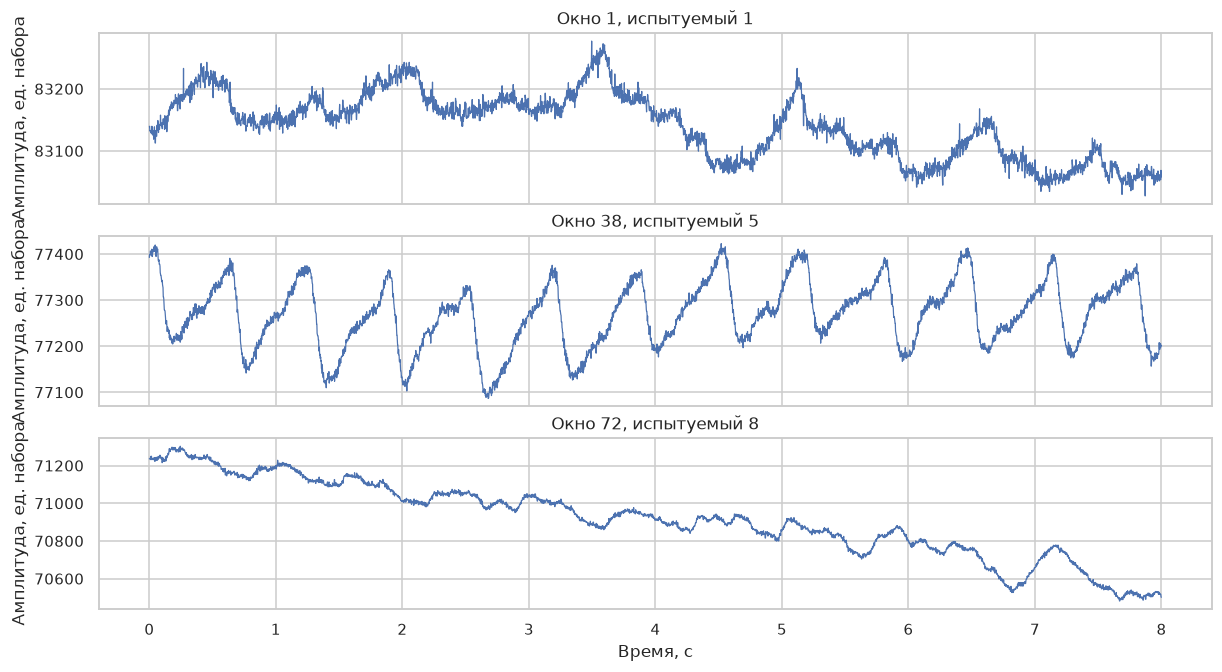

In [2]:
train_path = ROOT / "dataset/task2_2/train.npz"
external_path = ROOT / "dataset/task2_2/test_features.npz"
with np.load(train_path, allow_pickle=False) as archive:
    signals = archive["X"].squeeze(-1)
    subject_ids = archive["subject_id"]
    window_ids = archive["window_id"]
    source_metadata = json.loads(str(archive["meta_json"]))
fs = float(source_metadata["sampling_rate_hz"])
assert signals.ndim == 2 and np.isfinite(signals).all()
assert signals.shape[1] / fs == source_metadata["window_seconds"]
assert len(np.unique(window_ids)) == len(signals)
display(pd.DataFrame({"Испытуемый": subject_ids}).value_counts().rename("Число окон").sort_index())
print(f"Фактически в train: {signals.shape}, частота {fs:g} Гц.")
fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True, layout="constrained")
for ax, idx in zip(axes, [0, len(signals) // 2, len(signals) - 1]):
    ax.plot(np.arange(signals.shape[1]) / fs, signals[idx], linewidth=0.8)
    ax.set(title=f"Окно {window_ids[idx]}, испытуемый {subject_ids[idx]}", ylabel="Амплитуда, ед. набора")
axes[-1].set_xlabel("Время, с")
save_figure("raw_signals.png")

## Признаки
Для каждого окна посчитал разброс амплитуды, изменение между отсчётами,
спектральные и пульсовые признаки. Перед поиском пиков применил фильтр
0.5–8 Гц. Частоту найденных пиков нельзя автоматически считать точным
пульсом: при движении часть пиков может быть артефактами.
Параметры фильтра и список признаков заданы заранее, без меток активности.

In [3]:
FEATURE_NAMES = ["STD", "Размах 5–95%", "Шероховатость", "Асимметрия", "Эксцесс",
                 "Энтропия спектра", "Доля 0.5–3.5 Гц", "Доля 3.5–15 Гц",
                 "Доминирующая частота", "Пики/с", "Средний интервал", "STD интервалов", "Автокорреляция"]


def extract_features(windows, sampling_rate):
    sos = butter(4, [0.5, 8.0], btype="bandpass", fs=sampling_rate, output="sos")
    rows = []
    for raw in np.asarray(windows, dtype=float):
        filtered = sosfiltfilt(sos, raw)
        frequencies, power = welch(raw, fs=sampling_rate, nperseg=min(2048, len(raw)))
        total = power.sum() + 1e-12
        distribution = power / total
        cardiac = (frequencies >= 0.5) & (frequencies < 3.5)
        motion = (frequencies >= 3.5) & (frequencies < 15)
        peaks, _ = find_peaks(filtered, distance=int(0.25 * sampling_rate),
                              prominence=max(1e-12, 0.15 * filtered.std()))
        intervals = np.diff(peaks) / sampling_rate
        centered = filtered - filtered.mean()
        autocorrelation = np.correlate(centered, centered, mode="full")[len(centered) - 1:]
        autocorrelation /= max(autocorrelation[0], 1e-12)
        segment = autocorrelation[int(0.25 * sampling_rate):int(2 * sampling_rate)]
        rows.append([
            raw.std(), np.quantile(raw, 0.95) - np.quantile(raw, 0.05),
            np.abs(np.diff(raw)).mean() / max(raw.std(), 1e-12),
            skew(filtered), kurtosis(filtered),
            -(distribution * np.log(np.maximum(distribution, 1e-12))).sum() / np.log(len(power)),
            power[cardiac].sum() / total, power[motion].sum() / total,
            frequencies[cardiac][power[cardiac].argmax()],
            len(peaks) / (len(raw) / sampling_rate),
            intervals.mean() if len(intervals) else 0.0,
            intervals.std() if len(intervals) else 0.0, segment.max(),
        ])
    result = np.asarray(rows)
    assert np.isfinite(result).all(), "Проверьте пустые или постоянные сигналы"
    return result


features = extract_features(signals, fs)
feature_table = pd.DataFrame(features, columns=FEATURE_NAMES)
feature_table.to_csv(OUT / "training_features.csv", index=False)
display(feature_table.agg(["mean", "std", "min", "max"]).T.round(3))

,mean,std,min,max
STD,135.373,90.351,35.964,634.881
Размах 5–95%,433.364,265.173,114.695,1839.778
Шероховатость,0.060,0.032,0.010,0.187
Асимметрия,0.016,0.328,-0.543,0.674
Эксцесс,-0.508,0.871,-1.277,4.333
Энтропия спектра,0.304,0.056,0.118,0.422
Доля 0.5–3.5 Гц,0.673,0.233,0.074,0.938
Доля 3.5–15 Гц,0.079,0.072,0.005,0.338
Доминирующая частота,1.399,0.438,0.732,3.174
Пики/с,1.875,0.441,1.000,3.000


## Нормализация и кластеризация
Основным вариантом заранее выбрал нормализацию признаков внутри каждого
испытуемого. Так убирается часть различий амплитуды и масштаба между людьми.
Для сравнения оставил вариант с одной общей нормализацией.

В обоих вариантах использую PCA до восьми компонент и KMeans с тремя
кластерами. Три — число активностей в условии. Параметры по меткам не подбираю.
Все нормализаторы и PCA обучаются только по обучающему архиву.

In [4]:
subject_scalers = {}
within_features = np.zeros_like(features)
for sid in np.unique(subject_ids):
    mask = subject_ids == sid
    subject_scalers[int(sid)] = StandardScaler().fit(features[mask])
    within_features[mask] = subject_scalers[int(sid)].transform(features[mask])
variants = {}
for name, matrix in [("Общая нормализация", features), ("Внутри испытуемого", within_features)]:
    scaler = StandardScaler().fit(matrix)
    scaled = scaler.transform(matrix)
    pca = PCA(n_components=8, svd_solver="full").fit(scaled)
    embedding = pca.transform(scaled)
    kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=30, random_state=SEED).fit(embedding)
    variants[name] = {"scaler": scaler, "pca": pca, "embedding": embedding,
                      "model": kmeans, "clusters": kmeans.labels_.copy(),
                      "silhouette": silhouette_score(embedding, kmeans.labels_)}
selected_name = "Внутри испытуемого"
selected = variants[selected_name]
clusters = selected["clusters"]
np.savez(OUT / "pipeline.npz", subject_ids=np.array(sorted(subject_scalers)),
         subject_mean=np.stack([subject_scalers[s].mean_ for s in sorted(subject_scalers)]),
         subject_scale=np.stack([subject_scalers[s].scale_ for s in sorted(subject_scalers)]),
         global_mean=selected["scaler"].mean_, global_scale=selected["scaler"].scale_,
         pca_mean=selected["pca"].mean_, pca_components=selected["pca"].components_,
         centers=selected["model"].cluster_centers_)
print("Основной вариант выбран до чтения prediction:", selected_name)

Основной вариант выбран до чтения prediction: Внутри испытуемого


## Назначения внешним окнам
Для каждого испытуемого беру среднее и масштаб из его обучающих окон.
Во внешнем архиве те же восемь человек. Для нового человека без обучающих
окон этот вариант потребовал бы отдельного способа нормализации.

In [5]:
with np.load(external_path, allow_pickle=False) as archive:
    external_signals = archive["X"].squeeze(-1)
    external_subject_ids = archive["subject_id"]
    external_ids = archive["window_id"]
assert len(np.unique(external_ids)) == len(external_ids)
assert set(external_ids).isdisjoint(window_ids)
assert set(external_subject_ids) <= set(subject_ids)
external_features = extract_features(external_signals, fs)
external_within = np.zeros_like(external_features)
for sid in np.unique(external_subject_ids):
    mask = external_subject_ids == sid
    external_within[mask] = subject_scalers[int(sid)].transform(external_features[mask])
external_embedding = selected["pca"].transform(selected["scaler"].transform(external_within))
external_clusters = selected["model"].predict(external_embedding)
submission = pd.DataFrame({"window_id": external_ids, "prediction": external_clusters})
assert len(submission) == len(external_ids) and not submission.isna().any().any()
np.testing.assert_array_equal(submission.window_id, external_ids)
submission.to_csv(ROOT / "outputs/task2_2_predictions.csv", index=False)
frozen_predictions_hash = hashlib.sha256((ROOT / "outputs/task2_2_predictions.csv").read_bytes()).hexdigest()
print(f"Зафиксированы {len(submission)} внешних назначения. Теперь можно прочитать метки обучения.")

Зафиксированы 24 внешних назначения. Теперь можно прочитать метки обучения.


## Сравнение с активностями
Только теперь читаю prediction. ARI и NMI использую для оценки, но не для
выбора нормализации или KMeans. Номера кластеров могут отличаться от номеров
активностей, поэтому обычная Accuracy между ними не имеет смысла.

In [6]:
with np.load(train_path, allow_pickle=False) as archive:
    labels = archive["prediction"]
    label_names = archive["label_names"].astype(str)
metrics = []
for name, result in variants.items():
    metrics.append({"Вариант": name, "ARI активности": adjusted_rand_score(labels, result["clusters"]),
                    "NMI активности": normalized_mutual_info_score(labels, result["clusters"]),
                    "Silhouette": result["silhouette"],
                    "ARI испытуемого": adjusted_rand_score(subject_ids, result["clusters"])})
metric_table = pd.DataFrame(metrics).set_index("Вариант")
display(metric_table.round(3))
metric_table.to_csv(OUT / "metrics.csv")
activity_names = label_names[labels]
activity_table = pd.crosstab(pd.Series(clusters, name="Кластер"), pd.Series(activity_names, name="Активность"))
activity_table = activity_table.reindex(index=range(N_CLUSTERS), columns=label_names, fill_value=0)
activity_table.to_csv(OUT / "cluster_activity.csv")
pd.DataFrame({"window_id": window_ids, "subject_id": subject_ids, "target": labels,
              "prediction": clusters}).to_csv(OUT / "training_assignments.csv", index=False)

,ARI активности,NMI активности,Silhouette,ARI испытуемого
Вариант,,,,
Общая нормализация,0.088,0.199,0.262,0.097
Внутри испытуемого,0.239,0.258,0.173,-0.023


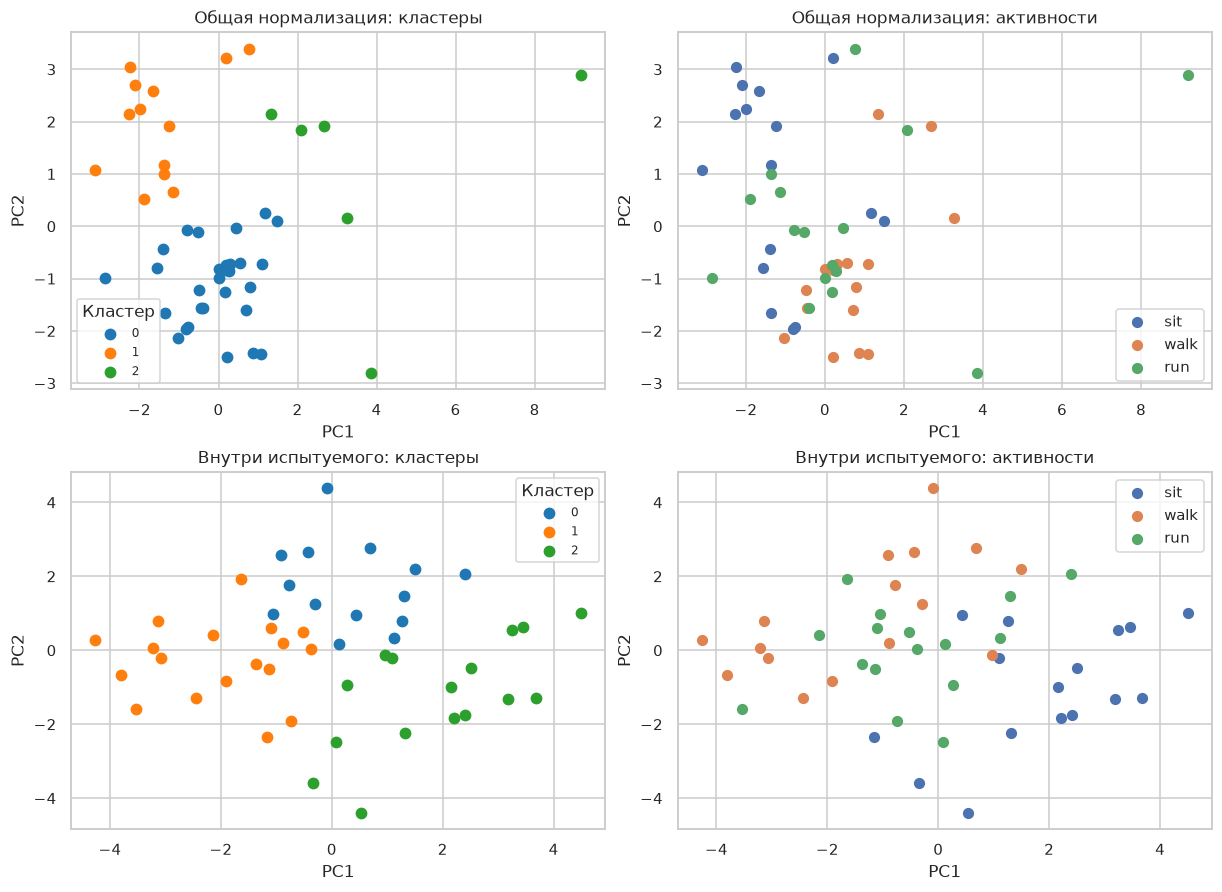

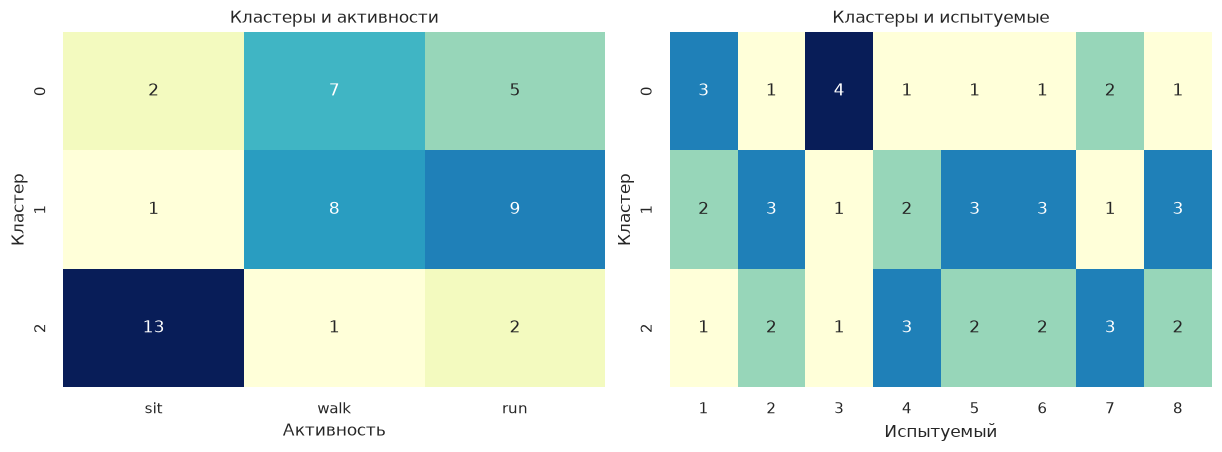

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
for row, (name, result) in enumerate(variants.items()):
    projection = result["embedding"][:, :2]
    for cluster_id in range(N_CLUSTERS):
        mask = result["clusters"] == cluster_id
        axes[row, 0].scatter(projection[mask, 0], projection[mask, 1], s=45,
                             label=str(cluster_id), color=sns.color_palette("tab10")[cluster_id])
    axes[row, 0].set_title(name + ": кластеры")
    axes[row, 0].legend(title="Кластер", fontsize=8)
    for class_id, activity in enumerate(label_names):
        mask = labels == class_id
        axes[row, 1].scatter(projection[mask, 0], projection[mask, 1], label=activity, s=40)
    axes[row, 1].set_title(name + ": активности")
    axes[row, 1].legend()
for ax in axes.flat:
    ax.set(xlabel="PC1", ylabel="PC2")
save_figure("pca_comparison.png")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
sns.heatmap(activity_table, annot=True, fmt="d", cmap="YlGnBu", cbar=False, ax=axes[0])
subject_table = pd.crosstab(pd.Series(clusters, name="Кластер"), pd.Series(subject_ids, name="Испытуемый"))
sns.heatmap(subject_table, annot=True, fmt="d", cmap="YlGnBu", cbar=False, ax=axes[1])
axes[0].set_title("Кластеры и активности")
axes[1].set_title("Кластеры и испытуемые")
save_figure("cluster_tables.png")

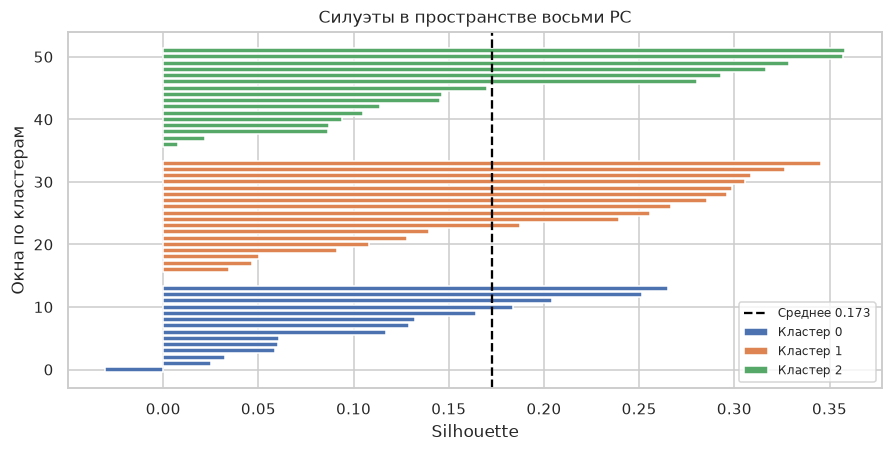

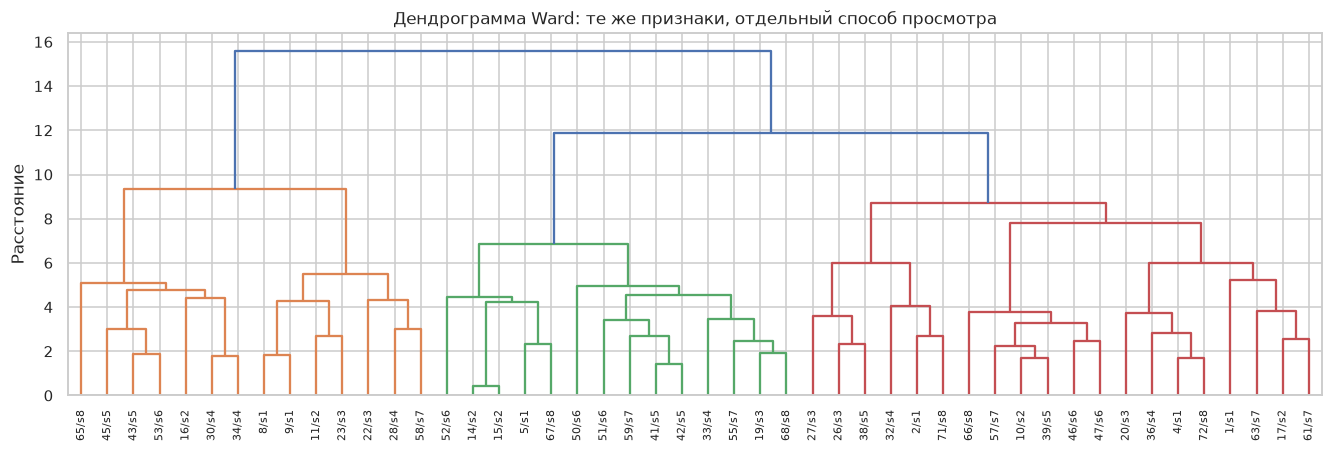

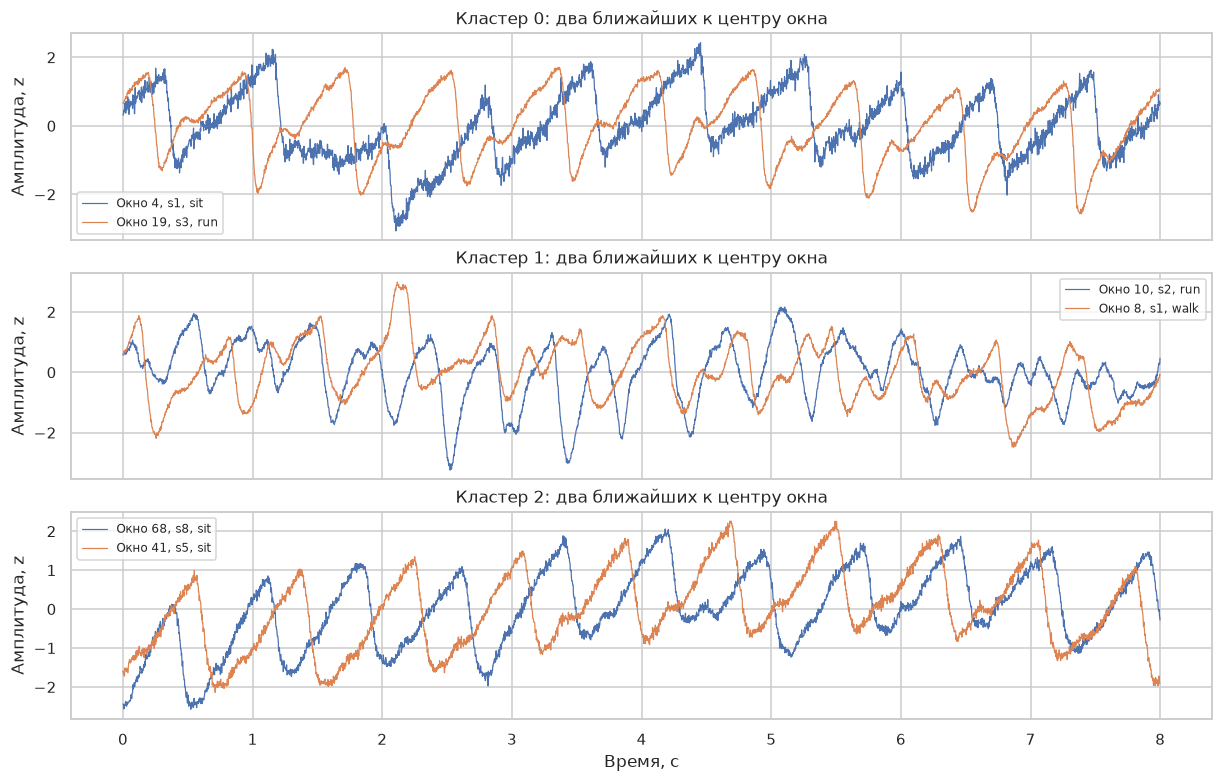

In [8]:
silhouettes = silhouette_samples(selected["embedding"], clusters)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
position = 0
for cluster_id in range(N_CLUSTERS):
    values = np.sort(silhouettes[clusters == cluster_id])
    ax.barh(np.arange(position, position + len(values)), values, label=f"Кластер {cluster_id}")
    position += len(values) + 2
ax.axvline(selected["silhouette"], color="black", linestyle="--", label=f"Среднее {selected['silhouette']:.3f}")
ax.set(xlabel="Silhouette", ylabel="Окна по кластерам", title="Силуэты в пространстве восьми PC")
ax.legend(fontsize=8)
save_figure("silhouette.png")

fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
dendrogram(linkage(selected["embedding"], method="ward"),
           labels=[f"{wid}/s{sid}" for wid, sid in zip(window_ids, subject_ids)],
           leaf_rotation=90, leaf_font_size=7, ax=ax)
ax.set(title="Дендрограмма Ward: те же признаки, отдельный способ просмотра", ylabel="Расстояние")
save_figure("dendrogram.png")

fig, axes = plt.subplots(N_CLUSTERS, 1, figsize=(11, 7), sharex=True, layout="constrained")
for cluster_id, ax in enumerate(axes):
    idx = np.flatnonzero(clusters == cluster_id)
    distances = np.linalg.norm(selected["embedding"][idx] - selected["model"].cluster_centers_[cluster_id], axis=1)
    for row in idx[np.argsort(distances)[:2]]:
        normalized = (signals[row] - signals[row].mean()) / max(signals[row].std(), 1e-12)
        ax.plot(np.arange(signals.shape[1]) / fs, normalized, linewidth=0.8,
                label=f"Окно {window_ids[row]}, s{subject_ids[row]}, {activity_names[row]}")
    ax.set(title=f"Кластер {cluster_id}: два ближайших к центру окна", ylabel="Амплитуда, z")
    ax.legend(fontsize=8)
axes[-1].set_xlabel("Время, с")
save_figure("typical_windows.png")

## Выводы
Нормализация убирает часть различий между людьми, но сама по себе не
гарантирует разделение активностей. Набор очень маленький, а движение
влияет на PPG и добавляет артефакты. Поэтому результат оцениваю по нескольким метрикам.

In [9]:
main_metrics = metric_table.loc[selected_name]
sit_cluster = activity_table["sit"].idxmax()
sit_purity = activity_table.loc[sit_cluster, "sit"] / activity_table.loc[sit_cluster].sum()
report = (
    "Королев Даниил, 636-02. Задание 2.2.\n\n"
    f"В train.npz {len(signals)} окон PPG по {signals.shape[1]} отсчётов, "
    f"{len(np.unique(subject_ids))} испытуемых, частота {fs:g} Гц. Метаданные описывают "
    "72 исходных окна; фактически они разделены на 48 обучающих и 24 внешних. "
    "Посчитал 13 амплитудных, спектральных и пульсовых признаков. Перед поиском "
    "пиков использовал полосовой фильтр 0.5–8 Гц; при нехватке пиков интервалы равны нулю.\n\n"
    "Сравнил общую нормализацию с нормализацией внутри человека. Основным заранее "
    "выбрал второй вариант, чтобы уменьшить влияние индивидуального масштаба. "
    "Далее StandardScaler, PCA до 8 компонент и KMeans, k=3, n_init=30, seed=42. "
    "Все преобразования обучены только на train. Внешние окна преобразованы "
    "параметрами соответствующего человека из train.\n\n"
    f"После фиксации кластеров прочитал метки: ARI={main_metrics['ARI активности']:.3f}, "
    f"NMI={main_metrics['NMI активности']:.3f}, silhouette={main_metrics['Silhouette']:.3f}. "
    f"ARI по испытуемым={main_metrics['ARI испытуемого']:.3f}. Номера кластеров "
    "не являются названиями активностей. "
    f"Доля sit в наиболее насыщенном им кластере — {sit_purity:.1%}. "
    "При сидении меньше движения, поэтому сигнал потенциально проще; ходьба "
    "и бег могут смешиваться из-за похожих артефактов и изменения пульса. "
    "По одним этим данным причины смешения доказать нельзя.\n\n"
    f"Сохранил {len(submission)} внешних назначения с исходными window_id. "
    "Метки не участвовали в выборе метода, признаков или нормализации. "
    "Набор мал, внешние окна принадлежат тем же людям; качество на новых "
    "испытуемых этим экспериментом не проверено."
)
assert len(report) <= 2000, len(report)
_ = (ROOT / "your-sollution/task2_2_report.md").write_text(report + "\n", encoding="utf-8")
display(Markdown(report))
assert hashlib.sha256((ROOT / "outputs/task2_2_predictions.csv").read_bytes()).hexdigest() == frozen_predictions_hash
summary = {"author": "Королев Даниил", "group": "636-02", "seed": SEED, "train_rows": len(signals),
           "external_rows": len(submission), "features": FEATURE_NAMES, "selected_method": selected_name,
           "selection_uses_activity_labels": False, "metrics": {k: float(v) for k, v in main_metrics.items()},
           "n_clusters": N_CLUSTERS, "pca_components": 8, "report_characters": len(report),
           "python": platform.python_version(),
           "source_sha256": {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in [train_path, external_path]},
           "predictions_sha256": frozen_predictions_hash}
_ = (OUT / "run_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Длина отчёта: {len(report)}.")

Королев Даниил, 636-02. Задание 2.2.

В train.npz 48 окон PPG по 4000 отсчётов, 8 испытуемых, частота 500 Гц. Метаданные описывают 72 исходных окна; фактически они разделены на 48 обучающих и 24 внешних. Посчитал 13 амплитудных, спектральных и пульсовых признаков. Перед поиском пиков использовал полосовой фильтр 0.5–8 Гц; при нехватке пиков интервалы равны нулю.

Сравнил общую нормализацию с нормализацией внутри человека. Основным заранее выбрал второй вариант, чтобы уменьшить влияние индивидуального масштаба. Далее StandardScaler, PCA до 8 компонент и KMeans, k=3, n_init=30, seed=42. Все преобразования обучены только на train. Внешние окна преобразованы параметрами соответствующего человека из train.

После фиксации кластеров прочитал метки: ARI=0.239, NMI=0.258, silhouette=0.173. ARI по испытуемым=-0.023. Номера кластеров не являются названиями активностей. Доля sit в наиболее насыщенном им кластере — 81.2%. При сидении меньше движения, поэтому сигнал потенциально проще; ходьба и бег могут смешиваться из-за похожих артефактов и изменения пульса. По одним этим данным причины смешения доказать нельзя.

Сохранил 24 внешних назначения с исходными window_id. Метки не участвовали в выборе метода, признаков или нормализации. Набор мал, внешние окна принадлежат тем же людям; качество на новых испытуемых этим экспериментом не проверено.

Длина отчёта: 1351.
